# Kumasi Flood-Risk Classifier

Seasonal flooding is a recurring problem in parts of Kumasi — low-lying, drainage-stressed areas such as Aboabo, Asawase, Suame and Sepe flood far more often after heavy rain than higher-ground areas like Ahodwo, Nhyiaeso or Danyame, largely because of poor drains, gutters choked with waste, and proximity to the Subin/Aboabo river system.

**This notebook is a different problem, domain, and dataset from the earlier house-pricing / breast-cancer notebooks in this exercise:**

* **Task**: binary classification — will a location experience **high** or **low** flood risk for a given rainfall event?
* **Dataset**: `KumasiFloodRisk.csv` — 900 simulated rainfall-event records across 12 Kumasi neighbourhoods, with rainfall intensity, drainage quality, gutter/waste blockage, distance to the nearest river, relative elevation, population density and prior flooding history.


As with the earlier notebooks, the code is organised as small functions plus one class (`load_data()`, `summarise()`, `FloodRiskClassifier`) instead of one long linear script, and the best of several classifiers is chosen automatically by cross-validated ROC-AUC.

## 1. Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
)
import joblib

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

NUMERIC_COLS = ["rainfall_mm", "distance_to_river_m", "elevation_index", "population_density", "prior_flood_events"]
CATEGORICAL_COLS = ["neighbourhood", "drainage_quality", "waste_blockage"]

## 2. Data loading as a function

In [ ]:
def load_data(path="KumasiFloodRisk.csv"):
    """Load the flood-risk records and encode the target as 0/1."""
    data = pd.read_csv(path)
    if data.isna().sum().sum() > 0:
        raise ValueError("Unexpected missing values in the dataset")
    data["target"] = (data["flood_risk"] == "high").astype(int)  # 1 = high risk
    return data

df = load_data()
print(f"Loaded {len(df)} records across {df['neighbourhood'].nunique()} neighbourhoods.")
df.head()

## 3. A single condensed EDA pass

In [ ]:
def summarise(data):
    print("Shape:", data.shape)
    print("\nOverall risk split:")
    print(data["flood_risk"].value_counts())

    by_area = data.groupby("neighbourhood")["target"].mean().sort_values(ascending=False)
    print("\nShare of 'high risk' events by neighbourhood:")
    print(by_area.round(2))

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    by_area.plot(kind="barh", ax=axes[0, 0], color="indianred")
    axes[0, 0].set_title("High-risk share by neighbourhood")
    axes[0, 0].invert_yaxis()

    sns.boxplot(x="flood_risk", y="rainfall_mm", data=data, ax=axes[0, 1], palette="Blues")
    axes[0, 1].set_title("Rainfall (mm) by risk level")

    sns.countplot(x="waste_blockage", hue="flood_risk", data=data,
                  order=["none", "moderate", "severe"], ax=axes[1, 0], palette="Set2")
    axes[1, 0].set_title("Gutter/waste blockage vs. risk")

    sns.boxplot(x="flood_risk", y="distance_to_river_m", data=data, ax=axes[1, 1], palette="Greens")
    axes[1, 1].set_title("Distance to river (m) by risk level")

    plt.tight_layout()
    plt.show()
    return by_area

by_area = summarise(df)

High-risk events are concentrated in Aboabo, Asawase, Sepe and Suame; higher rainfall, more severe gutter blockage and closer proximity to a river all line up with 'high' risk, as expected.

## 4. `FloodRiskClassifier`: preprocessing + model comparison + evaluation as a class

* `fit(X_train, y_train)` — cross-validates four candidate classifiers by ROC-AUC and keeps the best
* `evaluate(X_test, y_test)` — accuracy, precision, recall, F1, ROC-AUC
* `plot_diagnostics(...)` — confusion matrix + ROC curve
* `feature_importance()` — importances or coefficients, whichever the winning model supports
* `predict_risk(event_dict)` — classify one new rainfall event at a given location

In [ ]:
class FloodRiskClassifier:
    CANDIDATES = {
        "Logistic Regression": LogisticRegression(max_iter=5000),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "SVM (RBF)": SVC(probability=True, random_state=42),
    }

    def __init__(self, numeric_cols, categorical_cols, random_state=42):
        self.numeric_cols = numeric_cols
        self.categorical_cols = categorical_cols
        self.random_state = random_state
        self.preprocessor = ColumnTransformer([
            ("num", StandardScaler(), numeric_cols),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ])
        self.best_name = None
        self.pipeline = None
        self.cv_scores = {}

    def _make_pipeline(self, model):
        return Pipeline([("prep", self.preprocessor), ("model", model)])

    def fit(self, X_train, y_train):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=self.random_state)
        for name, model in self.CANDIDATES.items():
            scores = cross_val_score(self._make_pipeline(model), X_train, y_train, cv=skf, scoring="roc_auc")
            self.cv_scores[name] = scores
            print(f"{name:<20s} mean ROC-AUC = {scores.mean():.4f}   std = {scores.std():.4f}")

        self.best_name = max(self.cv_scores, key=lambda k: self.cv_scores[k].mean())
        self.pipeline = self._make_pipeline(self.CANDIDATES[self.best_name])
        self.pipeline.fit(X_train, y_train)
        print("\nSelected model:", self.best_name)
        return self

    def predict(self, X):
        return self.pipeline.predict(X)

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)[:, 1]

    def evaluate(self, X_test, y_test):
        y_pred = self.predict(X_test)
        y_proba = self.predict_proba(X_test)
        metrics = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_proba),
        }
        for k, v in metrics.items():
            print(f"{k:<10s}: {v:.4f}")
        return metrics, y_pred, y_proba

    def plot_diagnostics(self, y_test, y_pred, y_proba):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

        cm = confusion_matrix(y_test, y_pred)
        ConfusionMatrixDisplay(cm, display_labels=["low", "high"]).plot(ax=axes[0], colorbar=False)
        axes[0].set_title(f"{self.best_name}: confusion matrix")

        fpr, tpr, _ = roc_curve(y_test, y_proba)
        axes[1].plot(fpr, tpr, color="teal", label=f"AUC = {roc_auc_score(y_test, y_proba):.3f}")
        axes[1].plot([0, 1], [0, 1], "r--", linewidth=1)
        axes[1].set_xlabel("False positive rate")
        axes[1].set_ylabel("True positive rate")
        axes[1].set_title("ROC curve")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    def feature_importance(self, top_n=12):
        model = self.pipeline.named_steps["model"]
        cat_names = list(self.pipeline.named_steps["prep"]
                          .named_transformers_["cat"].get_feature_names_out(self.categorical_cols))
        names = self.numeric_cols + cat_names

        if hasattr(model, "feature_importances_"):
            values = model.feature_importances_
            label = f"{self.best_name} feature importances"
        elif hasattr(model, "coef_"):
            values = model.coef_[0]
            label = f"{self.best_name} coefficients (standardised / one-hot features)"
        else:
            print(f"{self.best_name} doesn't expose importances or coefficients directly.")
            return None

        series = pd.Series(values, index=names).abs().sort_values().tail(top_n)
        series.plot(kind="barh", figsize=(7, 6), color="slateblue")
        plt.title(label)
        plt.tight_layout()
        plt.show()
        return series

    def predict_risk(self, event):
        """Classify a single new rainfall event given as a dict of raw feature values."""
        row = pd.DataFrame([event])[self.numeric_cols + self.categorical_cols]
        proba = self.predict_proba(row)[0]
        label = "high" if proba >= 0.5 else "low"
        return label, proba

## 5. Driver: split the data, fit the model, evaluate it

In [ ]:
X = df[NUMERIC_COLS + CATEGORICAL_COLS]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = FloodRiskClassifier(NUMERIC_COLS, CATEGORICAL_COLS).fit(X_train, y_train)

Logistic Regression  mean ROC-AUC = 0.9778   std = 0.0071
Random Forest        mean ROC-AUC = 0.9616   std = 0.0087
Gradient Boosting    mean ROC-AUC = 0.9615   std = 0.0148
SVM (RBF)            mean ROC-AUC = 0.9717   std = 0.0103

Selected model: Logistic Regression


In [ ]:
metrics, y_pred, y_proba = clf.evaluate(X_test, y_test)

Accuracy  : 0.9167
Precision : 0.8800
Recall    : 0.9167
F1        : 0.8980
ROC-AUC   : 0.9904


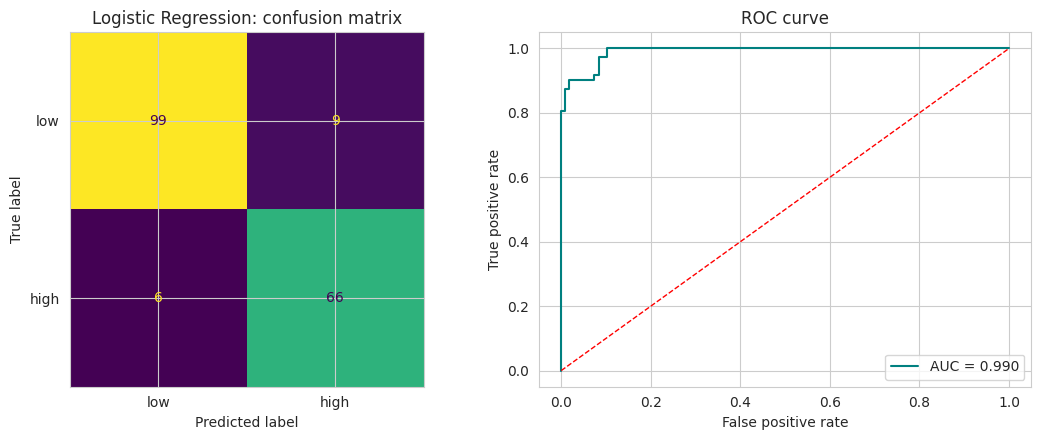

In [ ]:
clf.plot_diagnostics(y_test, y_pred, y_proba)

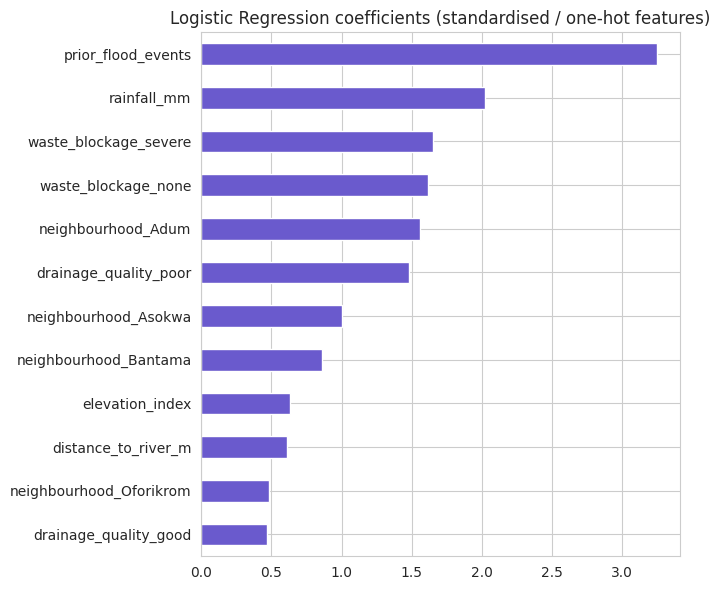

In [ ]:
_ = clf.feature_importance()

## 6. Scoring a brand-new rainfall event

The class's `predict_risk()` method scores one new situation directly — e.g. "what if there's a 90mm downpour in Aboabo tonight, with moderate gutter blockage?" — the way this model would actually be used by a local disaster-management or planning office.

In [ ]:
new_event = {
    "rainfall_mm": 90,
    "distance_to_river_m": 250,
    "elevation_index": 25,
    "population_density": 14000,
    "prior_flood_events": 3,
    "neighbourhood": "Aboabo",
    "drainage_quality": "poor",
    "waste_blockage": "moderate",
}

label, probability = clf.predict_risk(new_event)
print(f"Predicted flood risk: {label}  (P(high risk) = {probability:.3f})")

Predicted flood risk: high  (P(high risk) = 0.986)


## 7. Persist the fitted pipeline

In [ ]:
joblib.dump(clf.pipeline, "kumasi_flood_risk_model.joblib")
print("Saved pipeline for:", clf.best_name)

Saved pipeline for: Logistic Regression


## 8. Summary

* **Different problem, domain and dataset** from the earlier notebooks: classifying flood risk for Kumasi rainfall events, not house prices or tumour diagnosis.
* Built on a synthetic-but-realistic dataset (documented as such above) since no live Kumasi flood dataset could be fetched in this offline environment; risk is driven by rainfall, drainage quality, gutter blockage, river proximity, elevation and neighbourhood — the same factors cited in real flood-risk discussions of the city.
* Code is organised as `load_data()`, `summarise()`, and one `FloodRiskClassifier` class (fit / evaluate / plot_diagnostics / feature_importance / predict_risk), matching the function/class-based structure used earlier in this exercise.
* Four classifiers were screened by cross-validated ROC-AUC and the best kept automatically; the notebook ends with a live example of scoring one new rainfall event at a specific neighbourhood.